# Rounds: catching deteriorating patients when vitals are incomplete
**Datathon for Social Good 2025, Track 1 (Public Health Risk)**

Hospitals don't run out of equipment. They run out of time. On a busy ward, vitals get skipped, guessed, or go stale, and the standard early warning score quietly stops working. When a patient who could have been saved dies of a treatable complication, Medicare calls it *failure to rescue*.

This notebook has two parts:
1. **Patient level (Track 1 data):** we build **Rounds**, a model that predicts a patient's risk level even when some vitals are missing, and we work out which vitals a nurse should take first when time is short.
2. **Hospital level (CMS + CDC + HRSA data):** we measure where failure to rescue is worst in the US and who it affects, which tells us where a tool like Rounds would matter most.

**To run it:** Runtime, then Run all. The notebook downloads every data file it needs from our GitHub repo (the `data/` folder), so you don't need to upload anything.

In [1]:
# Setup
!pip -q install scikit-learn pandas matplotlib openpyxl

import os, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score, confusion_matrix, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
DATA_DIR = 'data'
OUT_DIR = 'outputs'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
# Load the data. In Colab, upload any file that isn't already in data/.
# All data lives in the data/ folder of our public GitHub repo, so anyone can press "Run all".
GITHUB_REPO = 'emill-y/rounds-datathon'   # <- change to your repo
BRANCH = 'main'
NEEDED = ['Health_Risk_Dataset.csv']

def get_files(names):
    import urllib.request
    for n in names:
        path = os.path.join(DATA_DIR, n)
        if os.path.exists(path):
            continue
        url = f'https://raw.githubusercontent.com/{GITHUB_REPO}/{BRANCH}/data/{n}'
        try:
            urllib.request.urlretrieve(url, path); print('downloaded', n)
        except Exception as e:
            try:   # fallback: upload by hand in Colab
                from google.colab import files
                print(f'Could not download {n} ({e}). Please upload it:')
                for name, content in files.upload().items():
                    open(os.path.join(DATA_DIR, name), 'wb').write(content)
            except ImportError:
                raise FileNotFoundError(f'Put {n} in {DATA_DIR}/ or set GITHUB_REPO')

get_files(NEEDED)
df = pd.read_csv(os.path.join(DATA_DIR, 'Health_Risk_Dataset.csv'))
print(df.shape)
df.head()

(1000, 10)


,Patient_ID,Respiratory_Rate,Oxygen_Saturation,O2_Scale,Systolic_BP,Heart_Rate,Temperature,Consciousness,On_Oxygen,Risk_Level
0,P0522,25,96,1,97,107,37.5,A,0,Medium
1,P0738,28,92,2,116,151,38.5,P,1,High
2,P0741,29,91,1,79,135,38.4,A,0,High
3,P0661,24,96,1,95,92,37.3,A,0,Medium
4,P0412,20,96,1,97,97,37.4,A,0,Low


## 1. A first look at the data
1,000 anonymized patients, 7 vital signs, and a risk label (Normal / Low / Medium / High). No missing values.

In [3]:
print(df.isna().sum().sum(), 'missing values')
print(df['Risk_Level'].value_counts())
df.describe().round(1)

0 missing values
Risk_Level
Medium    306
High      279
Low       255
Normal    160
Name: count, dtype: int64


,Respiratory_Rate,Oxygen_Saturation,O2_Scale,Systolic_BP,Heart_Rate,Temperature,On_Oxygen
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,21.5,92.6,1.1,106.2,98.5,37.9,0.3
std,5.3,4.5,0.3,17.9,19.7,1.1,0.4
min,12.0,74.0,1.0,50.0,60.0,35.6,0.0
25%,17.0,90.0,1.0,94.0,84.0,37.1,0.0
50%,20.0,94.0,1.0,109.0,95.5,37.8,0.0
75%,25.0,96.0,1.0,119.0,109.0,38.6,1.0
max,40.0,100.0,2.0,146.0,163.0,41.8,1.0


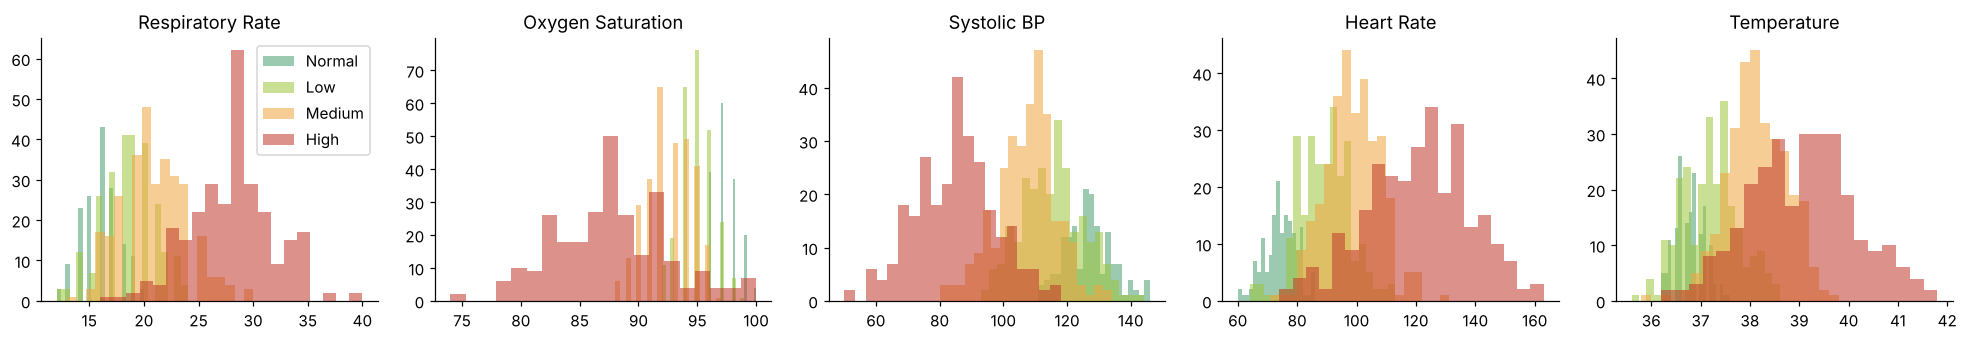

In [4]:
CLASSES = ['Normal', 'Low', 'Medium', 'High']
COLORS = {'Normal': '#4C9F70', 'Low': '#9BC53D', 'Medium': '#F2A541', 'High': '#C0392B'}
num_cols = ['Respiratory_Rate', 'Oxygen_Saturation', 'Systolic_BP', 'Heart_Rate', 'Temperature']
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, c in zip(axes, num_cols):
    for lvl in CLASSES:
        ax.hist(df.loc[df.Risk_Level == lvl, c], bins=20, alpha=0.55, color=COLORS[lvl], label=lvl)
    ax.set_title(c.replace('_', ' '))
axes[0].legend()
plt.tight_layout(); plt.show()

## 2. Discovery: the risk label is the NEWS2 score

The columns (respiratory rate, SpO2 with oxygen scale 1/2, supplemental oxygen, systolic BP, heart rate, temperature, ACVPU consciousness) are exactly the inputs of **NEWS2**, the UK Royal College of Physicians' National Early Warning Score. So we coded NEWS2 from the published 2017 chart and compared it with the labels.

NEWS2 risk bands: total 0 = Normal, 1-4 = Low, 5-6 or any single parameter scoring 3 = Medium, 7+ = High.

In [5]:
def band(x, cuts):
    # cuts = list of (upper_bound, points). A missing vital scores 0, the way it does on a paper chart.
    if pd.isna(x): return 0
    for hi, pts in cuts:
        if x <= hi: return pts
    return cuts[-1][1]

def news2_parts(r):
    rr   = band(r.Respiratory_Rate, [(8,3),(11,1),(20,0),(24,2),(1e9,3)])
    if pd.isna(r.Oxygen_Saturation): spo2 = 0
    elif r.O2_Scale == 2:           # scale 2 = patients with hypercapnic respiratory failure (e.g. COPD)
        x = r.Oxygen_Saturation
        spo2 = 3 if x<=83 else 2 if x<=85 else 1 if x<=87 else 0 if (x<=92 or not r.On_Oxygen) else 1 if x<=94 else 2 if x<=96 else 3
    else:
        spo2 = band(r.Oxygen_Saturation, [(91,3),(93,2),(95,1),(1e9,0)])
    air  = 2 * int(r.On_Oxygen)
    sbp  = band(r.Systolic_BP, [(90,3),(100,2),(110,1),(219,0),(1e9,3)])
    hr   = band(r.Heart_Rate, [(40,3),(50,1),(90,0),(110,1),(130,2),(1e9,3)])
    temp = band(r.Temperature, [(35.0,3),(36.0,1),(38.0,0),(39.0,1),(1e9,2)])
    cons = 0 if pd.isna(r.Consciousness) else (0 if r.Consciousness == 'A' else 3)
    return [rr, spo2, air, sbp, hr, temp, cons]

def news2_risk_row(r):
    p = news2_parts(r); total = sum(p)
    if total >= 7: return 'High'
    if total >= 5 or max(p) == 3: return 'Medium'
    if total >= 1: return 'Low'
    return 'Normal'

def news2_risk(d):
    return d.apply(news2_risk_row, axis=1)

df['NEWS2_total'] = df.apply(lambda r: sum(news2_parts(r)), axis=1)
df['NEWS2_risk'] = news2_risk(df)
print(f"NEWS2 reproduces the label for {(df.NEWS2_risk == df.Risk_Level).mean():.1%} of patients")
pd.crosstab(df.NEWS2_risk, df.Risk_Level).loc[CLASSES, CLASSES]

NEWS2 reproduces the label for 98.7% of patients


Risk_Level,Normal,Low,Medium,High
NEWS2_risk,,,,
Normal,160,0,0,0
Low,0,255,13,0
Medium,0,0,293,0
High,0,0,0,279


**98.7% match.** The only disagreements are 13 patients that NEWS2 calls Low but the data calls Medium, and all of them sit on the 3-4 point border.

What this means: with all 7 vitals in hand, a "most accurate classifier" just rebuilds a published formula. That isn't useful, because hospitals already have the formula. **The real problem is that the formula needs every vital, and on real wards vitals are often missing.**

## 3. The real problem: incomplete vitals

What happens on real wards (from the clinical literature):
- On general wards, vitals are usually taken every 4-8 hours, so a patient can deteriorate between checks.
- Respiratory rate is the vital most often skipped or written down as a "normal-looking" default like 18 or 20, even though it's one of the strongest early warning signs.
- Each extra patient per nurse is linked to about 7% higher odds of death and failure to rescue (Aiken et al., *JAMA* 2002).

On a paper chart, a vital that wasn't measured scores 0 points, which is the same as normal. So **we test every model on every possible combination of measured vitals** (63 combinations of the 6 bedside measurements). The oxygen scale and whether the patient is on oxygen are always known from the chart.

**Models compared**
| Model | What it is |
|---|---|
| Majority class | Always predicts the most common class (the floor) |
| NEWS2 (missing = normal) | What a ward actually does today |
| Logistic regression | Simple, interpretable ML baseline (median imputation + "was missing" flags) |
| **Rounds** | Gradient boosting that handles missing values natively |

**How the ML models learn to handle gaps:** during training we show each patient 12 extra times with random vitals hidden (each hidden with probability 0.45), so one model learns to work with any combination. **Evaluation** is 5-fold stratified cross-validation, so every patient is scored by a model that never saw them.

**Metrics:** macro-F1 (all four classes weighted equally), **High-risk recall** (the share of truly High-risk patients we flag as High), and the **dangerous miss rate** (truly High-risk patients labelled Low or Normal).

In [6]:
VITALS = ['Respiratory_Rate', 'Oxygen_Saturation', 'Systolic_BP', 'Heart_Rate', 'Temperature', 'Consciousness']
SHORT = {'Respiratory_Rate':'RR', 'Oxygen_Saturation':'SpO2', 'Systolic_BP':'BP', 'Heart_Rate':'HR', 'Temperature':'Temp', 'Consciousness':'ACVPU'}
CONTEXT = ['O2_Scale', 'On_Oxygen']
CONS_MAP = {'A':0, 'C':1, 'V':2, 'P':3, 'U':4}   # ACVPU, ordered from alert to unresponsive
base = df.drop(columns=['NEWS2_total', 'NEWS2_risk'])

def to_X(d):
    X = d[CONTEXT + VITALS].copy()
    X['Consciousness'] = X['Consciousness'].map(CONS_MAP)
    X['Shock_Index'] = X['Heart_Rate'] / X['Systolic_BP']    # HR/SBP, a standard shock marker
    return X.astype(float)

def hide(d, keep):
    m = d.copy()
    for v in VITALS:
        if v not in keep: m[v] = np.nan
    return m

def augment(d, rng, copies=12, p_drop=0.45):
    parts = [d]
    for _ in range(copies):
        m = d.copy()
        drop = rng.random((len(m), len(VITALS))) < p_drop
        for j, v in enumerate(VITALS): m.loc[drop[:, j], v] = np.nan
        parts.append(m)
    return pd.concat(parts, ignore_index=True)

def fit_rounds(train, rng):
    a = augment(train, rng)
    m = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=SEED)
    return m.fit(to_X(a), a['Risk_Level'])

def fit_logreg(train, rng):
    a = augment(train, rng)
    m = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000))
    return m.fit(to_X(a), a['Risk_Level'])

def score(y, p):
    y, p = pd.Series(list(y)), pd.Series(list(p)); hi = y == 'High'
    return dict(accuracy=accuracy_score(y, p),
                macro_f1=f1_score(y, p, labels=CLASSES, average='macro', zero_division=0),
                high_recall=(p[hi] == 'High').mean(),
                dangerous_miss=p[hi].isin(['Low', 'Normal']).mean())

SUBSETS = [s for k in range(1, 7) for s in itertools.combinations(VITALS, k)]
print(len(SUBSETS), 'vital combinations')

63 vital combinations


In [7]:
%%time
rng = np.random.default_rng(SEED)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, rr_rows, oof = [], [], []
majority = base['Risk_Level'].mode()[0]
fold_models = []

for fold, (tr, te) in enumerate(skf.split(base, base['Risk_Level'])):
    train, test = base.iloc[tr], base.iloc[te]
    rounds, logreg = fit_rounds(train, rng), fit_logreg(train, rng)
    fold_models.append(rounds)
    for s in SUBSETS:
        t = hide(test, s)
        preds = {'Majority class': [majority] * len(t),
                 'NEWS2 (missing = normal)': news2_risk(t),
                 'Logistic regression': logreg.predict(to_X(t)),
                 'Rounds': rounds.predict(to_X(t))}
        for name, p in preds.items():
            rows.append({**score(test['Risk_Level'], p), 'model': name, 'fold': fold,
                         'n_vitals': len(s), 'vitals': '+'.join(SHORT[v] for v in s)})
    # Experiment: respiratory rate written down as 18 without actually counting it
    guessed = test.copy(); guessed['Respiratory_Rate'] = 18
    for name, p in {'NEWS2, all vitals really measured': news2_risk(test),
                    'NEWS2, RR guessed as 18': news2_risk(guessed),
                    'Rounds, RR guessed as 18': rounds.predict(to_X(guessed)),
                    'Rounds, RR left blank': rounds.predict(to_X(hide(test, [v for v in VITALS if v != 'Respiratory_Rate'])))}.items():
        rr_rows.append({**score(test['Risk_Level'], p), 'scenario': name})
    pr = rounds.predict_proba(to_X(test))
    f = test[['Patient_ID', 'Risk_Level']].copy()
    for i, c in enumerate(rounds.classes_): f['P_' + c] = pr[:, i]
    oof.append(f)

res = pd.DataFrame(rows)
by_subset = res.groupby(['model', 'n_vitals', 'vitals'])[['accuracy', 'macro_f1', 'high_recall', 'dangerous_miss']].mean().reset_index()
by_k = by_subset.groupby(['model', 'n_vitals'])[['accuracy', 'macro_f1', 'high_recall', 'dangerous_miss']].mean().reset_index()
by_subset.to_csv(f'{OUT_DIR}/metrics_by_vital_subset.csv', index=False)
by_k.to_csv(f'{OUT_DIR}/metrics_by_number_of_vitals.csv', index=False)

CPU times: user 1min 18s, sys: 651 ms, total: 1min 19s
Wall time: 27.2 s


## 4. Results: how many high-risk patients does each approach catch?
The numbers below are averaged over every combination with that many vitals measured, using held-out patients only.

In [8]:
order = ['Majority class', 'NEWS2 (missing = normal)', 'Logistic regression', 'Rounds']
for metric in ['high_recall', 'dangerous_miss', 'macro_f1']:
    print('\n', metric)
    display(by_k.pivot(index='n_vitals', columns='model', values=metric)[order].round(3))


 high_recall


model,Majority class,NEWS2 (missing = normal),Logistic regression,Rounds
n_vitals,,,,
1,0.0,0.000,0.790,0.772
2,0.0,0.273,0.862,0.860
3,0.0,0.634,0.917,0.923
4,0.0,0.876,0.951,0.952
5,0.0,0.972,0.971,0.970
6,0.0,1.000,0.982,0.982



 dangerous_miss


model,Majority class,NEWS2 (missing = normal),Logistic regression,Rounds
n_vitals,,,,
1,0.0,0.538,0.059,0.070
2,0.0,0.214,0.018,0.017
3,0.0,0.065,0.006,0.004
4,0.0,0.014,0.003,0.002
5,0.0,0.002,0.002,0.001
6,0.0,0.000,0.000,0.000



 macro_f1


model,Majority class,NEWS2 (missing = normal),Logistic regression,Rounds
n_vitals,,,,
1,0.117,0.227,0.612,0.592
2,0.117,0.428,0.754,0.738
3,0.117,0.617,0.836,0.827
4,0.117,0.764,0.894,0.888
5,0.117,0.882,0.933,0.933
6,0.117,0.988,0.965,0.965


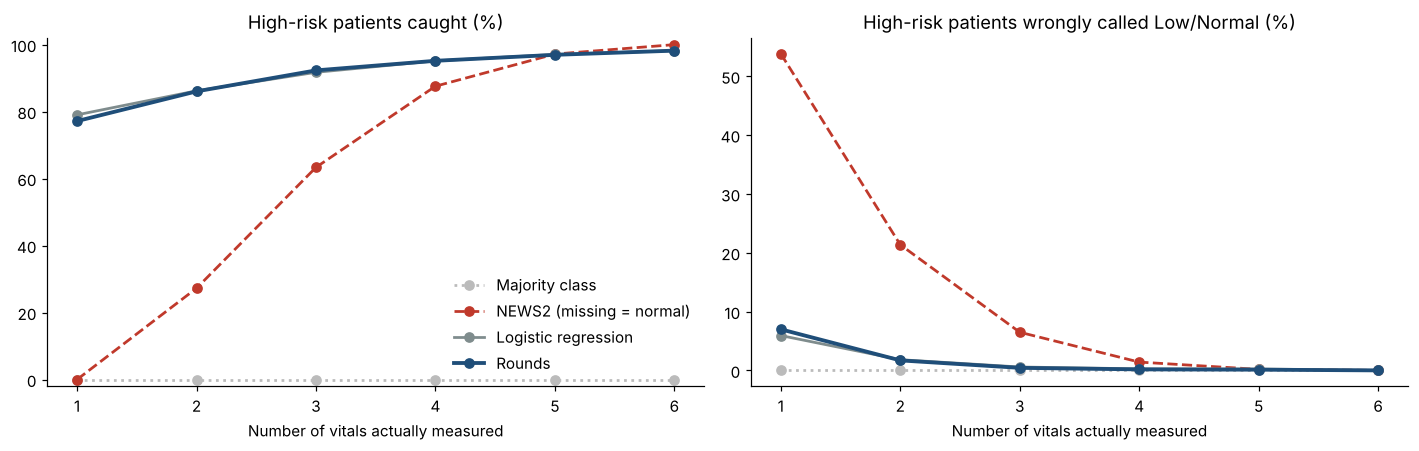

In [9]:
style = {'Majority class': ('#BBBBBB', ':'), 'NEWS2 (missing = normal)': ('#C0392B', '--'),
         'Logistic regression': ('#7F8C8D', '-'), 'Rounds': ('#1F4E79', '-')}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name in order:
    s = by_k[by_k.model == name]; c, ls = style[name]
    axes[0].plot(s.n_vitals, s.high_recall * 100, ls, color=c, marker='o', lw=2.5 if name == 'Rounds' else 1.8, label=name)
    axes[1].plot(s.n_vitals, s.dangerous_miss * 100, ls, color=c, marker='o', lw=2.5 if name == 'Rounds' else 1.8, label=name)
axes[0].set(title='High-risk patients caught (%)', xlabel='Number of vitals actually measured', ylim=(-2, 102))
axes[1].set(title='High-risk patients wrongly called Low/Normal (%)', xlabel='Number of vitals actually measured')
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_high_recall_vs_vitals.png', dpi=200); plt.show()

**What we found**
- **With every vital measured, NEWS2 is essentially perfect** (it's the formula behind the labels). That's the ceiling, not something we can beat.
- **As soon as vitals are missing, NEWS2 falls apart.** With 2 of 6 vitals measured it flags only about 27% of truly High-risk patients and calls about 21% of them Low or Normal. With 3 vitals measured it flags about 63%.
- **Rounds keeps catching them:** about 86% with 2 vitals and 92% with 3, with dangerous misses under 2%.
- **Logistic regression does about as well as gradient boosting.** The gain comes from *learning to reason about what's missing*, not from model complexity. That's good news for a hospital, because a simple, auditable model works.

## 5. Experiment: a guessed respiratory rate is worse than a blank
Here we take every test patient and write their respiratory rate down as 18, the classic "looks normal" default.

In [10]:
rr_res = pd.DataFrame(rr_rows).groupby('scenario')[['accuracy', 'high_recall', 'dangerous_miss']].mean()
rr_res = rr_res.loc[['NEWS2, all vitals really measured', 'NEWS2, RR guessed as 18', 'Rounds, RR guessed as 18', 'Rounds, RR left blank']]
rr_res.to_csv(f'{OUT_DIR}/guessed_rr_experiment.csv')
rr_res.round(3)

,accuracy,high_recall,dangerous_miss
scenario,,,
"NEWS2, all vitals really measured",0.987,1.000,0.000
"NEWS2, RR guessed as 18",0.826,0.939,0.007
"Rounds, RR guessed as 18",0.892,0.857,0.000
"Rounds, RR left blank",0.927,0.968,0.000


A guessed "18" drops NEWS2's accuracy from 98.7% to about 83% and makes it miss about 6% of High-risk patients. When Rounds is told honestly that RR wasn't measured, it keeps 97% of High-risk patients flagged. **Takeaway for the ward: leave it blank rather than guess, and let the model account for it.**

## 6. The 60-second check: which vitals should a nurse take first?
For each number of measurements, we find the combination that catches the most High-risk patients.

In [11]:
r = by_subset[by_subset.model == 'Rounds'].sort_values(['n_vitals', 'high_recall'], ascending=[True, False])
best = r.groupby('n_vitals').head(3)
best[['n_vitals', 'vitals', 'high_recall', 'dangerous_miss', 'macro_f1']].round(3)

,n_vitals,vitals,high_recall,dangerous_miss,macro_f1
192,1,RR,0.835,0.018,0.640
190,1,BP,0.831,0.050,0.612
193,1,SpO2,0.806,0.068,0.710
201,2,RR+BP,0.939,0.004,0.735
206,2,SpO2+BP,0.918,0.011,0.808
207,2,SpO2+HR,0.914,0.007,0.843
220,3,RR+SpO2+BP,0.971,0.000,0.898
215,3,RR+BP+HR,0.953,0.000,0.833
222,3,RR+SpO2+Temp,0.950,0.004,0.885
235,4,RR+SpO2+BP+ACVPU,0.975,0.000,0.899


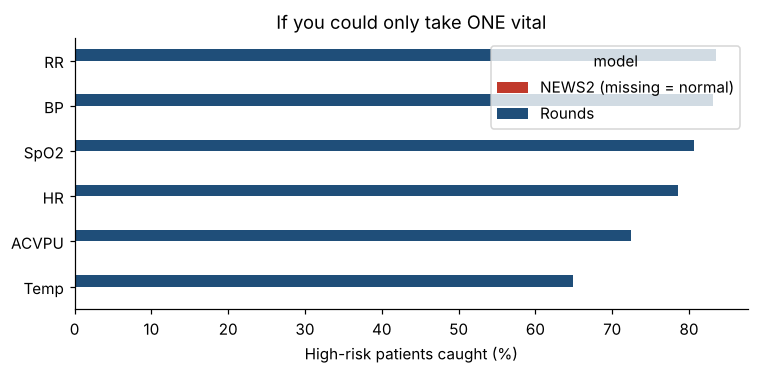

In [12]:
one = by_subset[(by_subset.n_vitals == 1) & by_subset.model.isin(['Rounds', 'NEWS2 (missing = normal)'])]
p = one.pivot(index='vitals', columns='model', values='high_recall').sort_values('Rounds')
ax = (p * 100).plot.barh(color=['#C0392B', '#1F4E79'], figsize=(7, 3.5))
ax.set(xlabel='High-risk patients caught (%)', ylabel='', title='If you could only take ONE vital')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_single_vital.png', dpi=200); plt.show()

**Priority order: Respiratory rate, then SpO2, then blood pressure.** With only these three, Rounds catches about 97% of High-risk patients and calls none of them Low or Normal. Respiratory rate, the vital most often skipped, is the single most informative one.

(We also tried an adaptive version that picks the next vital for each patient based on uncertainty. It wasn't better than this simple fixed order at catching High-risk patients, so we kept the simple order, which nurses can also memorize.)

## 7. Is Rounds' risk probability trustworthy? (calibration, full vitals)

Brier score for P(High): 0.0068


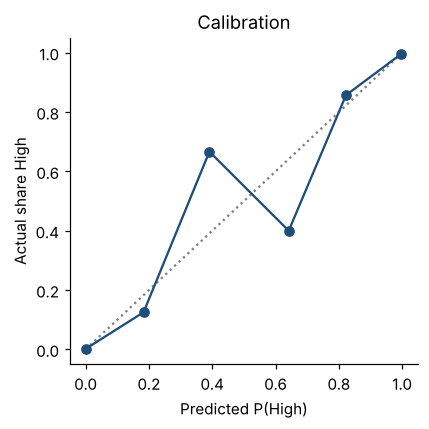

In [13]:
oof_df = pd.concat(oof)
y_high = (oof_df.Risk_Level == 'High').astype(int)
print('Brier score for P(High):', round(brier_score_loss(y_high, oof_df.P_High), 4))
bins = pd.cut(oof_df.P_High, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True)
cal = pd.DataFrame({'predicted': oof_df.P_High, 'actual': y_high}).groupby(bins, observed=True).mean()
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], ':', color='grey')
plt.plot(cal.predicted, cal.actual, 'o-', color='#1F4E79'); plt.xlabel('Predicted P(High)'); plt.ylabel('Actual share High')
plt.title('Calibration'); plt.tight_layout(); plt.show()

## 8. Rounds on a ward: who to check first
This is the tool itself. A nurse has a list of patients with whatever was last charted, and Rounds ranks them by the probability they are High risk and says which vital to take next (the next one in the priority order that hasn't been measured).

In [14]:
final_model = fit_rounds(base, np.random.default_rng(SEED))   # trained on all 1,000 patients
PRIORITY = ['Respiratory_Rate', 'Oxygen_Saturation', 'Systolic_BP', 'Heart_Rate', 'Consciousness', 'Temperature']

def rounds_triage(ward):
    w = ward.copy()
    P = final_model.predict_proba(to_X(w))
    for i, c in enumerate(final_model.classes_): w['P_' + c] = P[:, i].round(2)
    w['Rounds_risk'] = final_model.classes_[P.argmax(1)]
    w['NEWS2_today'] = news2_risk(w)
    w['Measure_next'] = w.apply(lambda r: next((SHORT[v] for v in PRIORITY if pd.isna(r[v])), 'all done'), axis=1)
    return w.sort_values('P_High', ascending=False)

# A night-shift ward: six real patients from the dataset, with the vitals that typically get skipped removed
demo_ids = base.groupby('Risk_Level').sample(2, random_state=7)['Patient_ID'].head(6)
ward = base[base.Patient_ID.isin(demo_ids)].copy()
rng_demo = np.random.default_rng(3)
for v in VITALS:
    ward.loc[rng_demo.random(len(ward)) < 0.5, v] = np.nan
ward.insert(0, 'Bed', range(1, len(ward) + 1))
cols = ['Bed', 'Patient_ID'] + VITALS + ['NEWS2_today', 'Rounds_risk', 'P_High', 'Measure_next', 'Risk_Level']
rounds_triage(ward)[cols].rename(columns={'Risk_Level': 'True risk (hidden from nurse)'})

,Bed,Patient_ID,Respiratory_Rate,Oxygen_Saturation,Systolic_BP,Heart_Rate,Temperature,Consciousness,NEWS2_today,Rounds_risk,P_High,Measure_next,True risk (hidden from nurse)
841,6,P0726,NaN,79.0,77.0,NaN,39.3,P,High,High,1.00,RR,High
815,5,P0848,NaN,NaN,NaN,NaN,NaN,NaN,Low,High,0.53,RR,High
491,2,P0598,NaN,NaN,80.0,NaN,37.9,NaN,Medium,Medium,0.24,RR,Medium
282,1,P0240,NaN,NaN,NaN,83.0,37.1,NaN,Low,Low,0.00,RR,Low
577,4,P0471,25.0,NaN,111.0,102.0,38.4,A,Medium,Medium,0.00,SpO2,Medium
541,3,P0272,15.0,95.0,111.0,NaN,NaN,A,Low,Low,0.00,HR,Low


## 9. Limitations and bias
- **The labels are a formula, not outcomes.** We predict NEWS2 risk, not death or ICU transfer. NEWS2 is validated, but it's still a proxy, and our model inherits its blind spots.
- **1,000 patients, one source, no demographics.** We can't check whether performance differs by race, sex, age, or language, so a real deployment would need that audit first.
- **Pulse oximeters overestimate oxygen saturation in patients with darker skin** (Sjoding et al., *NEJM* 2020). Any score that leans on SpO2, including NEWS2 and Rounds, could under-triage Black patients. That's one more reason RR comes first in our priority order.
- **Missingness in our tests is systematic, not observed.** We tested every possible combination of missing vitals instead of real missing-data logs, which the dataset doesn't include. Real wards may skip vitals in patterns linked to how sick the patient looks.
- **The dataset has no time dimension**, so we can't show how *early* Rounds flags a patient, only how *accurately* it flags them from partial information.
- **Rounds is decision support, not a decision.** A ranking should never mean a low-ranked patient gets skipped.

---
# Part 2: Where is failure to rescue worst?
CMS publishes, for nearly every US hospital, the **Inpatient Surgical Complications Mortality Rate** (ISCMR, the successor to PSI-04 "failure to rescue"): deaths per 1,000 surgical patients who developed a serious, treatable complication.

**Data we join (all public):**
| File | Source | Join key | What it gives us |
|---|---|---|---|
| Complications_and_Deaths-Hospital.csv | CMS Provider Data | Facility ID | Failure-to-rescue rate (ISCMR) and cases per hospital |
| Hospital_General_Information.csv | CMS Provider Data | Facility ID | Ownership, emergency services |
| HCAHPS-Hospital.csv | CMS Provider Data | Facility ID | Patient survey: "got help as soon as needed", nurse communication, staff coordination |
| SVI_2022_US_COUNTY.csv | CDC/ATSDR | county name + state | Social Vulnerability Index |
| BCD_HPSA_FCT_DET_PC.csv | HRSA | county FIPS | Primary care shortage areas, rural status |

The raw CMS and HRSA downloads are large (HCAHPS is about 170MB), so the repo stores trimmed copies that keep only the measures and columns used here. `src/make_trimmed_data.py` recreates them from the raw downloads.

In [15]:
HOSP_FILES = ['Complications_and_Deaths-Hospital.csv', 'Hospital_General_Information.csv', 'HCAHPS-Hospital.csv',
              'SVI_2022_US_COUNTY.csv', 'BCD_HPSA_FCT_DET_PC.csv']
get_files(HOSP_FILES)

In [16]:
import re
def norm_county(s):
    s = str(s).upper().replace('.', '').replace("'", '').strip()
    s = re.sub(r'\b(COUNTY|PARISH|BOROUGH|CITY AND BOROUGH|CENSUS AREA|MUNICIPALITY|MUNICIPIO)\b', '', s)
    s = s.replace('SAINT ', 'ST ')
    return re.sub(r'\s+', ' ', s).strip()

# 1) Failure to rescue per hospital
c = pd.read_csv(f'{DATA_DIR}/Complications_and_Deaths-Hospital.csv', dtype=str)
ftr = c[c['Measure ID'] == 'ISCMR'].copy()
ftr['FTR_rate'] = pd.to_numeric(ftr['Score'], errors='coerce')          # deaths per 1,000 patients with a serious complication
ftr['FTR_cases'] = pd.to_numeric(ftr['Denominator'], errors='coerce')
ftr = ftr.dropna(subset=['FTR_rate', 'FTR_cases']).rename(columns={'Compared to National': 'FTR_vs_national'})
ftr = ftr[['Facility ID', 'Facility Name', 'City/Town', 'State', 'County/Parish', 'FTR_rate', 'FTR_cases', 'FTR_vs_national']]
print(len(ftr), 'hospitals report a failure-to-rescue rate')

# 2) Hospital info
g = pd.read_csv(f'{DATA_DIR}/Hospital_General_Information.csv', dtype=str)[['Facility ID', 'Hospital Ownership', 'Emergency Services']]

# 3) Patient survey (only the columns we need, to save memory)
want = {'H_COMP_3_LINEAR_SCORE': 'Help_ASAP_score', 'H_COMP_1_LINEAR_SCORE': 'Nurse_comm_score', 'H_COMP_9_LINEAR_SCORE': 'Staff_coordination_score'}
h = pd.read_csv(f'{DATA_DIR}/HCAHPS-Hospital.csv', dtype=str, usecols=['Facility ID', 'HCAHPS Measure ID', 'HCAHPS Linear Mean Value'])
h = h[h['HCAHPS Measure ID'].isin(want)]
h['val'] = pd.to_numeric(h['HCAHPS Linear Mean Value'], errors='coerce')
h = h.pivot_table(index='Facility ID', columns='HCAHPS Measure ID', values='val').rename(columns=want).reset_index()

# 4) Social Vulnerability Index by county
svi = pd.read_csv(f'{DATA_DIR}/SVI_2022_US_COUNTY.csv', dtype={'FIPS': str}, encoding='utf-8-sig').replace(-999, np.nan)
svi['FIPS'] = svi['FIPS'].str.zfill(5)
svi['county_key'] = svi['COUNTY'].map(norm_county) + '|' + svi['ST_ABBR']
svi['Pop_density'] = svi['E_TOTPOP'] / svi['AREA_SQMI']
svi = svi[['FIPS', 'county_key', 'COUNTY', 'ST_ABBR', 'RPL_THEMES', 'RPL_THEME1', 'RPL_THEME2', 'RPL_THEME3', 'RPL_THEME4',
           'EP_UNINSUR', 'EP_AGE65', 'Pop_density']].rename(columns={
    'COUNTY': 'County', 'ST_ABBR': 'ST', 'RPL_THEMES': 'SVI_overall', 'RPL_THEME1': 'SVI_socioeconomic', 'RPL_THEME2': 'SVI_household',
    'RPL_THEME3': 'SVI_minority', 'RPL_THEME4': 'SVI_housing_transport', 'EP_UNINSUR': 'Pct_uninsured', 'EP_AGE65': 'Pct_65plus'})

# 5) Health professional shortage areas (primary care), active designations only
p = pd.read_csv(f'{DATA_DIR}/BCD_HPSA_FCT_DET_PC.csv', dtype=str,
                usecols=['HPSA Status', 'Designation Type', 'HPSA Score', 'Rural Status', 'State and County Federal Information Processing Standard Code'])
p = p[p['HPSA Status'].isin(['Designated', 'Proposed For Withdrawal']) &
      p['Designation Type'].isin(['Geographic HPSA', 'High Needs Geographic HPSA', 'HPSA Population'])]
p['FIPS'] = p['State and County Federal Information Processing Standard Code'].str.zfill(5)
p['HPSA Score'] = pd.to_numeric(p['HPSA Score'], errors='coerce')
p['rural'] = p['Rural Status'].isin(['Rural', 'Partially Rural'])
hpsa = p.groupby('FIPS').agg(HPSA_designations=('HPSA Score', 'size'), HPSA_max_score=('HPSA Score', 'max'), Rural=('rural', 'max')).reset_index()

# Join everything
hosp = ftr.merge(g, on='Facility ID', how='left').merge(h, on='Facility ID', how='left')
hosp['county_key'] = hosp['County/Parish'].map(norm_county) + '|' + hosp['State']
hosp = hosp.merge(svi, on='county_key', how='left').merge(hpsa, on='FIPS', how='left')
hosp['HPSA_designations'] = hosp['HPSA_designations'].fillna(0)
hosp['In_shortage_area'] = (hosp['HPSA_designations'] > 0).astype(int)
hosp['Rural'] = hosp['Rural'].fillna(False).astype(bool).astype(int)
print(f"matched to a county: {hosp.FIPS.notna().mean():.1%}")
hosp.head()

2316 hospitals report a failure-to-rescue rate
matched to a county: 97.4%


,Facility ID,Facility Name,City/Town,State,County/Parish,FTR_rate,FTR_cases,FTR_vs_national,Hospital Ownership,Emergency Services,...,SVI_household,SVI_minority,SVI_housing_transport,Pct_uninsured,Pct_65plus,Pop_density,HPSA_designations,HPSA_max_score,Rural,In_shortage_area
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,DOTHAN,AL,HOUSTON,66.37,715.0,Worse Than the National Rate,Government - Hospital District or Authority,Yes,...,0.7499,0.7251,0.3936,11.7,18.2,184.607208,0.0,NaN,0,0
1,010005,MARSHALL MEDICAL CENTERS,BOAZ,AL,MARSHALL,78.60,44.0,Worse Than the National Rate,Government - Hospital District or Authority,Yes,...,0.9087,0.5425,0.2504,11.1,17.2,173.056295,1.0,13.0,1,1
2,010006,NORTH ALABAMA MEDICAL CENTER,FLORENCE,AL,LAUDERDALE,97.49,363.0,Worse Than the National Rate,Proprietary,Yes,...,0.4219,0.4636,0.5568,9.5,20.1,141.208002,1.0,12.0,1,1
3,010011,ST. VINCENT'S EAST,BIRMINGHAM,AL,JEFFERSON,73.31,185.0,Worse Than the National Rate,Voluntary non-profit - Private,Yes,...,0.6109,0.8766,0.6017,9.0,16.3,604.805142,1.0,12.0,0,1
4,010012,DEKALB REGIONAL MEDICAL CENTER,FORT PAYNE,AL,DE KALB,47.47,34.0,No Different Than the National Rate,Proprietary,Yes,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0,0


## 10. How many deaths are excess?
We use the best-performing quarter of hospitals as an achievable benchmark. For each hospital, excess deaths = (its rate - benchmark rate) x its cases / 1,000, counting only hospitals above the benchmark.

In [17]:
bench = hosp.FTR_rate.quantile(0.25)
hosp['Deaths_est'] = hosp.FTR_rate * hosp.FTR_cases / 1000
hosp['Excess_deaths'] = (hosp.FTR_rate - bench).clip(lower=0) * hosp.FTR_cases / 1000
print(f"Benchmark (best quartile): {bench:.1f} deaths per 1,000")
print(f"Patients with serious complications: {hosp.FTR_cases.sum():,.0f}   deaths: {hosp.Deaths_est.sum():,.0f}  (2-year window)")
print(f"Excess deaths vs benchmark: {hosp.Excess_deaths.sum():,.0f} over 2 years, about {hosp.Excess_deaths.sum()/2:,.0f} per year")
print('Hospitals flagged by CMS as worse than national:', (hosp.FTR_vs_national == 'Worse Than the National Rate').sum())

Benchmark (best quartile): 45.4 deaths per 1,000
Patients with serious complications: 972,330   deaths: 47,303  (2-year window)
Excess deaths vs benchmark: 6,774 over 2 years, about 3,387 per year
Hospitals flagged by CMS as worse than national: 272


In [18]:
def summarize(gr):
    return pd.Series({'hospitals': len(gr), 'cases': gr.FTR_cases.sum(),
                      'FTR_rate (per 1,000, case-weighted)': np.average(gr.FTR_rate, weights=gr.FTR_cases),
                      'excess_deaths_2yr': gr.Excess_deaths.sum(),
                      '% worse than national': 100 * (gr.FTR_vs_national == 'Worse Than the National Rate').mean()})

hosp['SVI_quartile'] = pd.qcut(hosp.SVI_overall, 4, labels=['Q1 least vulnerable', 'Q2', 'Q3', 'Q4 most vulnerable'])
hosp['Help_quartile'] = pd.qcut(hosp.Help_ASAP_score.rank(method='first'), 4, labels=['Q1 slowest help', 'Q2', 'Q3', 'Q4 fastest help'])
tabs = {
  'Community vulnerability (CDC SVI)': hosp.dropna(subset=['SVI_quartile']).groupby('SVI_quartile', observed=True).apply(summarize, include_groups=False),
  'How fast patients get help (HCAHPS)': hosp.dropna(subset=['Help_ASAP_score']).groupby('Help_quartile', observed=True).apply(summarize, include_groups=False),
  'Rural county (HRSA)': hosp.groupby('Rural').apply(summarize, include_groups=False),
  'Primary care shortage area (HRSA)': hosp.groupby('In_shortage_area').apply(summarize, include_groups=False)}
for k, t in tabs.items():
    print('\n' + k); display(t.round(1))


Community vulnerability (CDC SVI)


,hospitals,cases,"FTR_rate (per 1,000, case-weighted)",excess_deaths_2yr,% worse than national
SVI_quartile,,,,,
Q1 least vulnerable,564.0,204099.0,47.1,1132.0,6.6
Q2,564.0,228762.0,49.7,1551.2,8.9
Q3,564.0,283619.0,46.6,1800.7,13.3
Q4 most vulnerable,564.0,225657.0,52.1,2155.0,18.8



How fast patients get help (HCAHPS)


,hospitals,cases,"FTR_rate (per 1,000, case-weighted)",excess_deaths_2yr,% worse than national
Help_quartile,,,,,
Q1 slowest help,573.0,246012.0,52.1,2263.4,17.8
Q2,572.0,322229.0,48.0,2000.1,12.8
Q3,572.0,259686.0,47.2,1611.6,11.4
Q4 fastest help,572.0,142276.0,46.6,882.0,5.6



Rural county (HRSA)


,hospitals,cases,"FTR_rate (per 1,000, case-weighted)",excess_deaths_2yr,% worse than national
Rural,,,,,
0,1153.0,594986.0,46.3,3372.6,10.0
1,1163.0,377344.0,52.3,3401.4,13.5



Primary care shortage area (HRSA)


,hospitals,cases,"FTR_rate (per 1,000, case-weighted)",excess_deaths_2yr,% worse than national
In_shortage_area,,,,,
0,490.0,207753.0,46.1,1062.2,5.9
1,1826.0,764577.0,49.3,5711.8,13.3


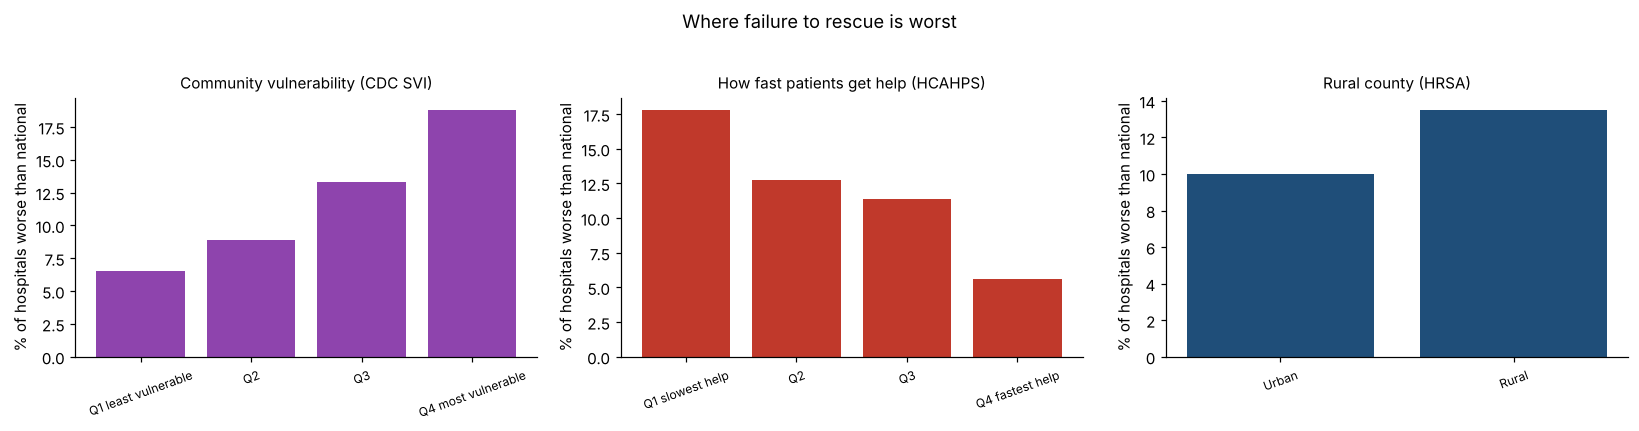

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (k, col) in zip(axes, [('Community vulnerability (CDC SVI)', '#8E44AD'), ('How fast patients get help (HCAHPS)', '#C0392B'), ('Rural county (HRSA)', '#1F4E79')]):
    t = tabs[k]['% worse than national']
    t.index = [str(i) if k != 'Rural county (HRSA)' else ('Urban' if i == 0 else 'Rural') for i in t.index]
    ax.bar(t.index, t.values, color=col); ax.set_title(k, fontsize=10); ax.set_ylabel('% of hospitals worse than national')
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
plt.suptitle('Where failure to rescue is worst', y=1.02); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_ftr_gaps.png', dpi=200, bbox_inches='tight'); plt.show()

## 11. Can we predict which hospitals have high failure-to-rescue rates?
We regress each hospital's rate on community and hospital features, evaluated with 5-fold cross-validation against a mean baseline. The aim isn't to replace CMS's measurement but to find which features go with a rescue gap, so resources can go to similar hospitals that don't yet report enough cases to be measured.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

hosp['Emergency'] = (hosp['Emergency Services'] == 'Yes').astype(int)
hosp['Gov'] = hosp['Hospital Ownership'].str.startswith('Government', na=False).astype(int)
hosp['Nonprofit'] = hosp['Hospital Ownership'].str.startswith('Voluntary', na=False).astype(int)
hosp['Proprietary'] = (hosp['Hospital Ownership'] == 'Proprietary').astype(int)
FEATS = ['SVI_overall', 'SVI_socioeconomic', 'SVI_household', 'SVI_minority', 'SVI_housing_transport', 'Pct_uninsured', 'Pct_65plus',
         'Pop_density', 'HPSA_designations', 'HPSA_max_score', 'Rural', 'Help_ASAP_score', 'Nurse_comm_score',
         'Staff_coordination_score', 'FTR_cases', 'Emergency', 'Gov', 'Nonprofit', 'Proprietary']
X, y = hosp[FEATS].astype(float), hosp.FTR_rate
kf = KFold(5, shuffle=True, random_state=SEED)
gbr = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=3, min_samples_leaf=40, random_state=SEED)
hp = {'Mean baseline': np.zeros(len(y)),
      'Linear regression': cross_val_predict(make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression()), X, y, cv=kf),
      'Gradient boosting': cross_val_predict(gbr, X, y, cv=kf)}
for tr, te in kf.split(X): hp['Mean baseline'][te] = y.iloc[tr].mean()
top = y >= y.quantile(0.75)
hm = pd.DataFrame([{'model': k, 'R2': r2_score(y, v), 'MAE (deaths per 1,000)': mean_absolute_error(y, v),
                    'precision flagging worst 25%': top[v >= np.quantile(v, 0.75)].mean()} for k, v in hp.items()])
hm.round(3)

,model,R2,"MAE (deaths per 1,000)",precision flagging worst 25%
0,Mean baseline,-0.000,9.274,0.247
1,Linear regression,0.196,8.356,0.399
2,Gradient boosting,0.228,8.108,0.454


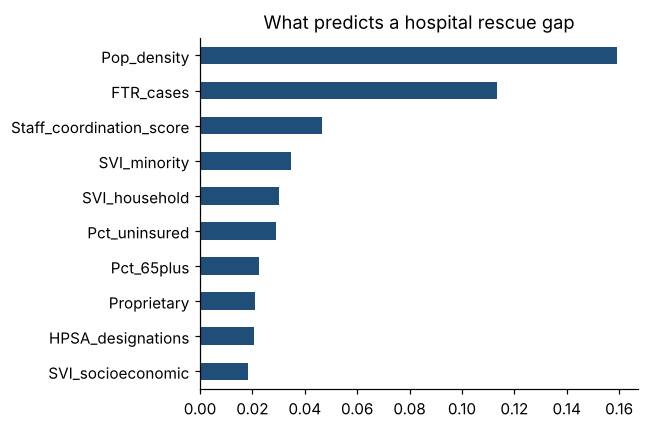

Pop_density                -0.28
Nurse_comm_score           -0.17
Staff_coordination_score   -0.15
Nonprofit                  -0.15
FTR_cases                  -0.13
Help_ASAP_score            -0.10
SVI_minority               -0.08
HPSA_max_score             -0.06
HPSA_designations          -0.04
SVI_housing_transport      -0.00
Gov                         0.02
Pct_65plus                  0.06
Emergency                   0.06
SVI_overall                 0.13
SVI_socioeconomic           0.15
Proprietary                 0.17
Rural                       0.18
Pct_uninsured               0.19
SVI_household               0.21
Name: FTR_rate, dtype: float64

In [21]:
gbr.fit(X, y)
pi = permutation_importance(gbr, X, y, n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
imp.tail(10).plot.barh(color='#1F4E79', figsize=(6, 4), title='What predicts a hospital rescue gap')
plt.tight_layout(); plt.show()
hosp[FEATS + ['FTR_rate']].corr(method='spearman')['FTR_rate'].drop('FTR_rate').sort_values().round(2)

**What we found**
- About **3,400 excess deaths a year** compared with the best quarter of US hospitals.
- Hospitals in the **most socially vulnerable counties are 2.8x as likely** to be flagged worse than national (18.8% vs 6.6%), and they account for about a third of excess deaths.
- Where patients say they **don't get help quickly**, failure to rescue is higher (52.1 vs 46.6 per 1,000) and hospitals are **3.2x as likely** to be flagged worse.
- **Rural** counties have 39% of the cases but about half of the excess deaths.
- The hospital model beats the mean baseline (R² about 0.23 vs 0; it finds the worst-quartile hospitals 45% of the time vs 25% by chance). That's modest, which is honest: most variation is driven by things not in public data.

**Limitations (Part 2):** these are associations, not causes. ISCMR is risk-adjusted by CMS but covers only Medicare fee-for-service surgical patients. Counties are matched by name (about 97% matched). HCAHPS responses are subjective and have low response rates. "Rural" here means the county contains a rural or partially rural HRSA shortage designation.

## 12. Exports for the Tableau dashboard

In [22]:
# Patient level: every patient, their vitals, NEWS2, and Rounds' out-of-fold probabilities
pat = base.merge(oof_df.drop(columns='Risk_Level'), on='Patient_ID')
pat['NEWS2_total'] = pat.apply(lambda r: sum(news2_parts(r)), axis=1)
pat.to_csv(f'{OUT_DIR}/tableau_patients.csv', index=False)
by_subset.to_csv(f'{OUT_DIR}/tableau_vital_combinations.csv', index=False)
by_k.to_csv(f'{OUT_DIR}/tableau_by_number_of_vitals.csv', index=False)
# Hospital and county level
hosp.drop(columns=['county_key']).to_csv(f'{OUT_DIR}/tableau_hospitals.csv', index=False)
cty = hosp.dropna(subset=['FIPS']).groupby(['FIPS', 'County', 'ST']).apply(lambda gr: pd.Series({
    'hospitals': len(gr), 'cases': gr.FTR_cases.sum(), 'excess_deaths_2yr': gr.Excess_deaths.sum(),
    'FTR_rate_weighted': np.average(gr.FTR_rate, weights=gr.FTR_cases), 'SVI_overall': gr.SVI_overall.iloc[0],
    'Rural': gr.Rural.max(), 'Help_ASAP_score': gr.Help_ASAP_score.mean()}), include_groups=False).reset_index()
cty.to_csv(f'{OUT_DIR}/tableau_counties.csv', index=False)
print(os.listdir(OUT_DIR))

['fig_high_recall_vs_vitals.png', 'metrics_by_vital_subset.csv', 'tableau_hospitals.csv', 'guessed_rr_experiment.csv', 'fig_single_vital.png', 'tableau_patients.csv', 'tableau_by_number_of_vitals.csv', 'metrics_by_number_of_vitals.csv', 'tableau_vital_combinations.csv', 'tableau_counties.csv', 'fig_ftr_gaps.png']


## Tools used
Python (pandas, scikit-learn, matplotlib) in Google Colab. AI assistant used for debugging and code review. NEWS2 thresholds are from the Royal College of Physicians (2017).